# Customer Churn Prediction

**Goal:** predict which streaming-platform customers will churn, and turn the model into a *retention decision* (who to contact, at what threshold, for what expected dollar value).

### 🎯 Project Overview: Objectives, Solutions & Outcomes

#### 1. Objectives
*   **Goal:** Predict high-risk customer churn for a streaming platform to optimize retention campaign spend.
*   **Target:** Predict the binary `Churn` label (18.1% prevalence in training data) using demographical, account, subscription, and behavioral features.
*   **Business Constraint:** Instead of simple accuracy, optimize a cost-sensitive decision rule maximizing **Net Dollar Value** using custom assumptions: $15 offer cost, 12-month value horizon, and a 15% offer save rate.

#### 2. Technical Solutions
*   **Data Preparation:** Developed a stateless feature engineering module (`churn_features.py`) ensuring no train-test data leakage.
*   **Production Pipeline:** Built a robust scikit-learn `Pipeline` encapsulating categorical mode imputation, one-hot encoding, and a tuned **XGBoost Classifier** model.
*   **Decision Strategy:** Leveraged Stratified 5-Fold Cross-Validation out-of-fold probability predictions to map and locate the exact profit-optimal threshold rather than standard $F1$ or accuracy metrics.

#### 3. Realized Outcomes
*   **Performance:** Achieved an Out-Of-Fold ROC-AUC of **0.747** and PR-AUC of **0.399**, mirroring **0.748** ROC-AUC and **0.406** Average Precision on the held-out test set.
*   **Financial Impact:** Selected a profit-optimal decision threshold of **0.53**. Using this target, the model delivers a **Net Value of $5,598** on the test set compared to a massive loss of **-$1,106,704** if the campaign targeted everyone blindly.
*   **Deployment Ready:** Saved the fully self-contained pipeline, library dependencies, model card metadata, and reproducible API-ready scoring functions.

**What this notebook covers**

| # | Section | Why it matters |
|---|---|---|
| 1 | Setup | Importing Important Libraries |
| 2 | Data loading | Train / test / label merge, integrity checks |
| 3 | Data cleaning | Duplicates, ID overlap, missing target, dtype hygiene (no leakage) |
| 4 | EDA | Target balance, distributions, churn rate by segment, univariate signal |
| 5 | Feature engineering | Stateless features in an importable `.py` module (reused at serving time) |
| 6 | Pipeline + hyper-parameters | Leakage-safe `Pipeline`, optional `RandomizedSearchCV`, early stopping |
| 7 | Cross-validation | Stratified K-Fold, feature ablation, class-weight comparison |
| 8 | Threshold + business value | Cost-sensitive decision rule chosen **without** touching the test set |
| 9 | Final evaluation | ROC / PR / calibration / decile lift / confusion matrix with $ overlay |
| 10 | Explainability | XGBoost gain vs SHAP, local explanations, reason codes, action playbook |
| 11 | Save & reload | `model.joblib` + `model_card.json` + sanity check for deployment |

## 📊 Key Findings and Technical Insights

Based on the end-to-end execution of the pipeline, here is a consolidated look at our findings:

### 1. Data & Signal Diagnostics
*   **Prevalence:** Churn prevalence is stable between training (**18.12%**) and testing (**18.25%**). A dummy "contact nobody" classifier sets our baseline accuracy at **81.75%**.
*   **Strongest Predictor:** `AccountAge` is the most critical driver. Newer users exhibit drastically higher risk of churn, which steadily drops as account tenure increases.
*   **Univariate Insights:** Categoricals show localized risk profiles; `SubscriptionType` and `PaymentMethod` (such as Electronic Checks) correlate strongly with distinct baseline churn levels.

### 2. Business Value Optimization
*   **Threshold Shift:** Selecting a threshold via standard F1 score maximizes targeting at **0.22**, but introducing costs shifts our profit-optimal threshold to **0.53**.
*   **Targeting Efficiency:**
    *   **Top Decile Lift:** The top 10% riskiest customers predicted by our model are **2.68x** more likely to churn than average.
    *   **Cumulative Capture:** Contacting only the top 3 deciles (30% of the customer base) captures **58.7%** of all churners.
*   **Calibration:** The unweighted XGBoost model is beautifully calibrated (closely tracing the diagonal line), validating that predicted probabilities correspond directly to real-world frequencies and can be safely used in financial computations.

### 3. Model Interpretability (SHAP)
*   **Tenure Risk:** `AccountAge` and engineered tenure landmarks (`IsLoyalUser`) are the main anchors of customer loyalty.
*   **Engagement Signals:** Lower `ActivityIntensity` and fewer `DownloadsPerSupportTicket` strongly pull customers toward churn risk.
*   **Service Friction:** High `SupportTicketsPerMonth` coupled with high spend (`MonthlyCharges`) acts as an immediate trigger for churn, recommending immediate service recovery strategies.

## 1. Importing Required Libraries

In [ ]:
import json, sys, platform, warnings, re
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn, xgboost, shap
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (StratifiedKFold, cross_validate, cross_val_predict,
                                     train_test_split, RandomizedSearchCV)
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             f1_score, precision_score, recall_score, accuracy_score,
                             roc_curve, precision_recall_curve, confusion_matrix)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

Loading data descriptions file. It contains the name and descriptions of the columns present in the dataset

In [ ]:
descp_df = pd.read_csv('/content/data_descriptions.csv')
descp_df

,Column_name,Column_type,Data_type,Description
0,AccountAge,Feature,integer,The age of the user's account in months.
1,MonthlyCharges,Feature,float,The amount charged to the user on a monthly ba...
2,TotalCharges,Feature,float,The total charges incurred by the user over th...
3,SubscriptionType,Feature,object,The type of subscription chosen by the user (B...
4,PaymentMethod,Feature,string,The method of payment used by the user.
5,PaperlessBilling,Feature,string,Indicates whether the user has opted for paper...
6,ContentType,Feature,string,The type of content preferred by the user (Mov...
7,MultiDeviceAccess,Feature,string,Indicates whether the user has access to the s...
8,DeviceRegistered,Feature,string,"The type of device registered by the user (TV,..."
9,ViewingHoursPerWeek,Feature,float,The number of hours the user spends watching c...


## 2. Data loading
The labels for the test set ship in a separate file, so we merge them on `CustomerID` using left join.

In [ ]:
train_df_raw = pd.read_csv('/content/train.csv')
test_feat = pd.read_csv('/content/test.csv')
test_sol = pd.read_csv('/content/test_sol.csv')

test_df_raw = test_feat.merge(test_sol[['CustomerID', 'Churn']], on='CustomerID', how="left")

print(f"train: {train_df_raw.shape} | test: {test_df_raw.shape}")
train_df_raw.head()

train: (243787, 21) | test: (104480, 21)


,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled,CustomerID,Churn
0,20,11.055215,221.104302,Premium,Mailed check,No,Both,No,Mobile,36.758104,63.531377,10,Sci-Fi,2.176498,4,Male,3,No,No,CB6SXPNVZA,0
1,57,5.175208,294.986882,Basic,Credit card,Yes,Movies,No,Tablet,32.450568,25.725595,18,Action,3.478632,8,Male,23,No,Yes,S7R2G87O09,0
2,73,12.106657,883.785952,Basic,Mailed check,Yes,Movies,No,Computer,7.395160,57.364061,23,Fantasy,4.238824,6,Male,1,Yes,Yes,EASDC20BDT,0
3,32,7.263743,232.439774,Basic,Electronic check,No,TV Shows,No,Tablet,27.960389,131.537507,30,Drama,4.276013,2,Male,24,Yes,Yes,NPF69NT69N,0
4,57,16.953078,966.325422,Premium,Electronic check,Yes,TV Shows,No,TV,20.083397,45.356653,20,Comedy,3.616170,4,Female,0,No,No,4LGYPK7VOL,0


## 3. Data cleaning
**Principle:** cleaning that needs *statistics* (imputation, scaling, encoding) is **not** done here — it happens inside the model `Pipeline` so it is fit on training folds only. Here we only do row-level hygiene that cannot leak.

In [ ]:
def audit(df, name):
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    }).sort_values("n_missing", ascending=False)
    print(f"--- {name}: {df.shape[0]:,} rows x {df.shape[1]} cols ---")
    display(out)

audit(train_df_raw, "train (raw)")
audit(test_df_raw, "test (raw)")

--- train (raw): 243,787 rows x 21 cols ---


,dtype,n_missing,pct_missing,n_unique
AccountAge,int64,0,0.0,119
MonthlyCharges,float64,0,0.0,243787
TotalCharges,float64,0,0.0,243787
SubscriptionType,object,0,0.0,3
PaymentMethod,object,0,0.0,4
PaperlessBilling,object,0,0.0,2
ContentType,object,0,0.0,3
MultiDeviceAccess,object,0,0.0,2
DeviceRegistered,object,0,0.0,4
ViewingHoursPerWeek,float64,0,0.0,243787


--- test (raw): 104,480 rows x 21 cols ---


,dtype,n_missing,pct_missing,n_unique
AccountAge,int64,0,0.0,119
MonthlyCharges,float64,0,0.0,104480
TotalCharges,float64,0,0.0,104480
SubscriptionType,object,0,0.0,3
PaymentMethod,object,0,0.0,4
PaperlessBilling,object,0,0.0,2
ContentType,object,0,0.0,3
MultiDeviceAccess,object,0,0.0,2
DeviceRegistered,object,0,0.0,4
ViewingHoursPerWeek,float64,0,0.0,104480


In [ ]:
def clean_categoricals(df):
    """Trim whitespace in text columns and use real NaN for missing (no statistics involved)."""
    df = df.copy()
    for c in df.columns.difference(['CustomerID', 'Churn']):
        if not pd.api.types.is_numeric_dtype(df[c]):
            s = df[c].astype("string").str.strip()
            df[c] = s.astype(object).where(s.notna(), np.nan)
    return df

train_df, test_df = clean_categoricals(train_df_raw), clean_categoricals(test_df_raw)
log = {"train_rows_raw": len(train_df), "test_rows_raw": len(test_df)}

# 1) Duplicates
log["train_full_row_duplicates"] = int(train_df.duplicated().sum())
log["train_duplicate_ids"] = int(train_df['CustomerID'].duplicated().sum())
train_df = train_df.drop_duplicates(subset='CustomerID', keep="first")
test_df = test_df.drop_duplicates(subset='CustomerID', keep="first")

# 2) Same customer in train AND test would leak the answer
overlap = set(train_df['CustomerID']) & set(test_df['CustomerID'])
log["ids_in_both_train_and_test"] = len(overlap)
if overlap:
    train_df = train_df[~train_df['CustomerID'].isin(overlap)]

# 3) Rows without a label cannot be used for supervised learning / evaluation
log["train_missing_target_dropped"] = int(train_df['Churn'].isna().sum())
log["test_missing_target_dropped"] = int(test_df['Churn'].isna().sum())
train_df = train_df.dropna(subset=['Churn']).reset_index(drop=True)
test_df = test_df.dropna(subset=['Churn']).reset_index(drop=True)
train_df['Churn'], test_df['Churn'] = train_df['Churn'].astype(int), test_df['Churn'].astype(int)

log["train_rows_final"], log["test_rows_final"] = len(train_df), len(test_df)
display(pd.Series(log, name="cleaning log").to_frame())

,cleaning log
train_rows_raw,243787
test_rows_raw,104480
train_full_row_duplicates,0
train_duplicate_ids,0
ids_in_both_train_and_test,0
train_missing_target_dropped,0
test_missing_target_dropped,0
train_rows_final,243787
test_rows_final,104480


In [ ]:
# Sanity checks (report only - we do not silently "fix" business data)
num_raw = train_df.select_dtypes(include=np.number).columns.drop(['Churn'], errors="ignore")
neg = (train_df[num_raw] < 0).sum()
print("Columns with negative values:", neg[neg > 0].to_dict() or "none")

if {"TotalCharges", "MonthlyCharges", "AccountAge"} <= set(train_df.columns):
    implied = (train_df["MonthlyCharges"] * train_df["AccountAge"]).replace(0, np.nan)
    print("\nTotalCharges / (MonthlyCharges x AccountAge) - should be near 1 if columns are consistent:")
    print((train_df["TotalCharges"] / implied).describe().round(3).to_string())

# Final X / y split. CustomerID is an identifier, never a feature.
feature_cols = [c for c in train_df.columns if c not in ('CustomerID', 'Churn')]
assert set(feature_cols) <= set(test_df.columns), "Train/test column mismatch"
X_train, y_train = train_df[feature_cols], train_df['Churn']
X_test,  y_test  = test_df[feature_cols],  test_df['Churn']
print(f"\nX_train {X_train.shape} | X_test {X_test.shape} | churn rate train {y_train.mean():.3%} / test {y_test.mean():.3%}")

Columns with negative values: none

TotalCharges / (MonthlyCharges x AccountAge) - should be near 1 if columns are consistent:
count    243787.0
mean          1.0
std           0.0
min           1.0
25%           1.0
50%           1.0
75%           1.0
max           1.0

X_train (243787, 19) | X_test (104480, 19) | churn rate train 18.123% / test 18.253%


## 4. Exploratory data analysis
EDA uses the **training set only** (the test set stays unseen). Where EDA suggests a modelling choice, we note it.

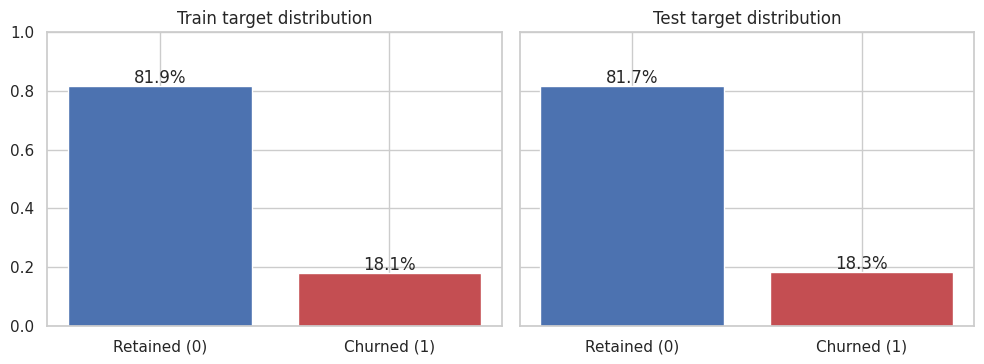

Imbalance ratio (neg:pos) = 4.52:1
Accuracy of the trivial 'nobody churns' model on test = 81.747%  <- the number any model must beat


In [ ]:
# 4.1 Target balance
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (name, y) in zip(axes, [("Train", y_train), ("Test", y_test)]):
    rate = y.value_counts(normalize=True).sort_index()
    ax.bar(["Retained (0)", "Churned (1)"], rate.values, color=["#4C72B0", "#C44E52"])
    for i, v in enumerate(rate.values): ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
    ax.set_title(f"{name} target distribution"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()
print(f"Imbalance ratio (neg:pos) = {(y_train == 0).sum() / (y_train == 1).sum():.2f}:1")
print(f"Accuracy of the trivial 'nobody churns' model on test = {1 - y_test.mean():.3%}  <- the number any model must beat")

,count,mean,std,min,25%,50%,75%,max
AccountAge,243787.0,60.083758,34.285143,1.000000,30.000000,60.000000,90.000000,119.000000
MonthlyCharges,243787.0,12.490695,4.327615,4.990062,8.738543,12.495555,16.238160,19.989957
TotalCharges,243787.0,750.741017,523.073273,4.991154,329.147027,649.878487,1089.317362,2378.723844
ViewingHoursPerWeek,243787.0,20.502179,11.243753,1.000065,10.763953,20.523116,30.219396,39.999723
AverageViewingDuration,243787.0,92.264061,50.505243,5.000547,48.382395,92.249992,135.908048,179.999275
ContentDownloadsPerMonth,243787.0,24.503513,14.421174,0.000000,12.000000,24.000000,37.000000,49.000000
UserRating,243787.0,3.002713,1.155259,1.000007,2.000853,3.002261,4.002157,4.999989
SupportTicketsPerMonth,243787.0,4.504186,2.872548,0.000000,2.000000,4.000000,7.000000,9.000000
WatchlistSize,243787.0,12.018508,7.193034,0.000000,6.000000,12.000000,18.000000,24.000000


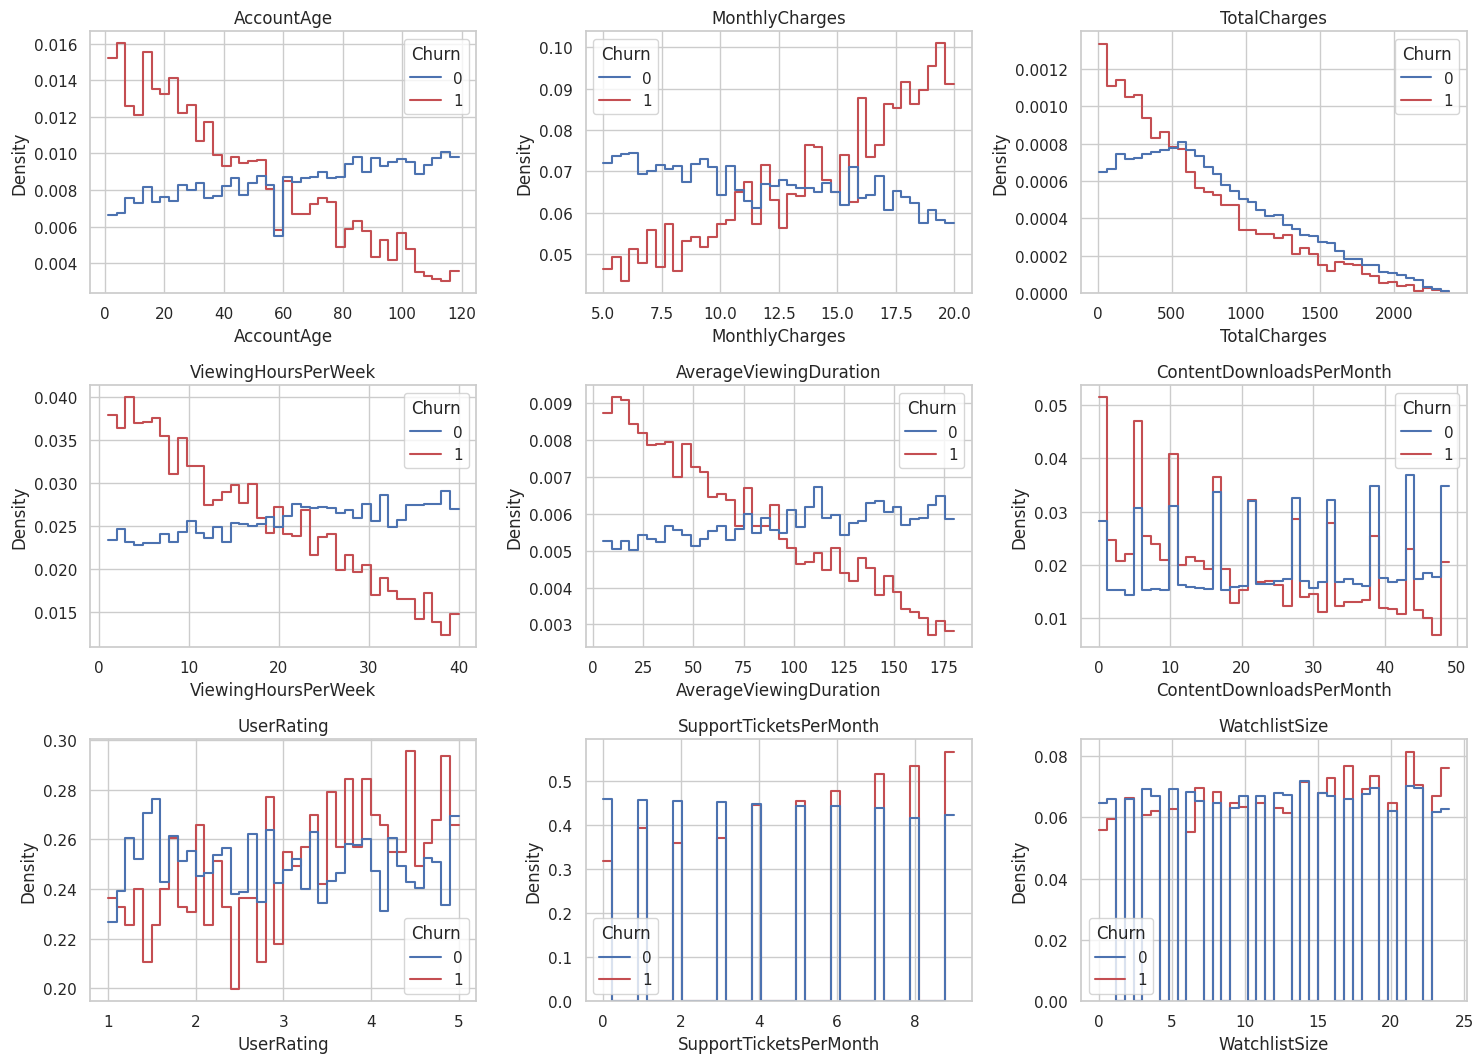

In [ ]:
# 4.2 Numeric features: summary + distributions by class
num_eda = X_train.select_dtypes(include=np.number).columns.tolist()
display(X_train[num_eda].describe().T)

sample = train_df.sample(min(30_000, len(train_df)), random_state=42)
ncols = 3; nrows = int(np.ceil(len(num_eda) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.6 * nrows))
for ax, c in zip(axes.ravel(), num_eda):
    sns.histplot(data=sample, x=c, hue='Churn', stat="density", common_norm=False,
                 element="step", fill=False, bins=40, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(c)
for ax in axes.ravel()[len(num_eda):]: ax.set_visible(False)
plt.tight_layout(); plt.show()

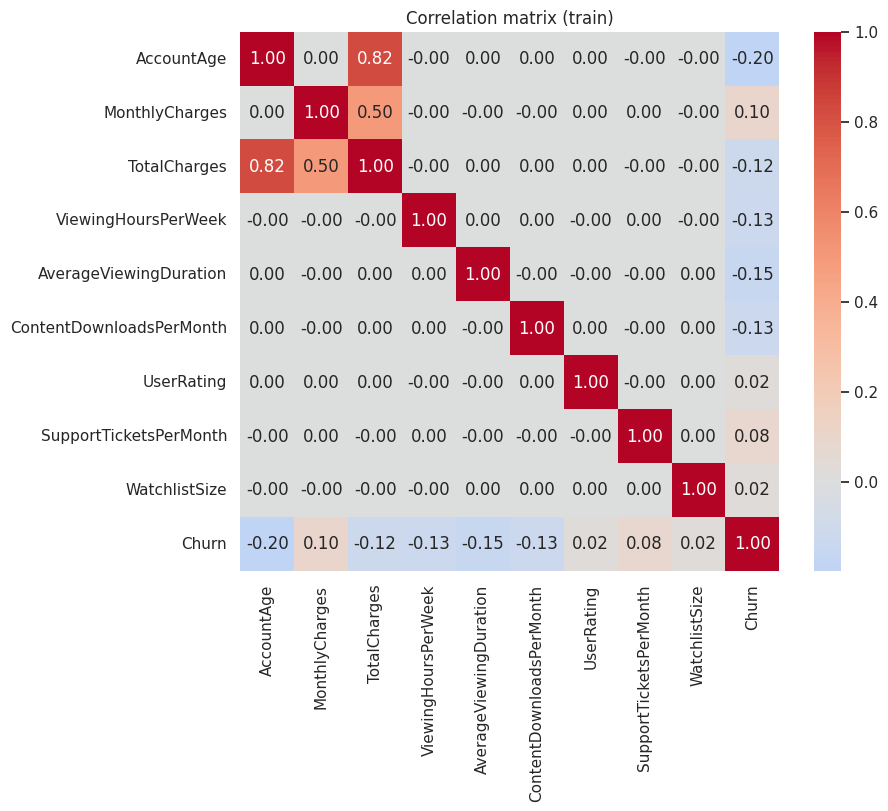

,feature,single_feature_auc,signal_strength
0,AccountAge,0.351840,0.148160
1,AverageViewingDuration,0.389908,0.110092
2,TotalCharges,0.401751,0.098249
3,ContentDownloadsPerMonth,0.402786,0.097214
4,ViewingHoursPerWeek,0.403600,0.096400
5,MonthlyCharges,0.575301,0.075301
6,SupportTicketsPerMonth,0.562684,0.062684
7,UserRating,0.516580,0.016580
8,WatchlistSize,0.516277,0.016277


In [ ]:
# 4.3 Correlation heatmap (numeric features + target)
corr = train_df[num_eda + ['Churn']].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=len(corr) <= 14, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (train)"); plt.show()

# 4.4 Univariate signal: AUC of each numeric feature used alone (0.5 = no signal)
rows = []
for c in num_eda:
    s = train_df[c].fillna(train_df[c].median())
    rows.append((c, roc_auc_score(train_df['Churn'], s)))
uni = pd.DataFrame(rows, columns=["feature", "single_feature_auc"])
uni["signal_strength"] = (uni["single_feature_auc"] - 0.5).abs()
uni = uni.sort_values("signal_strength", ascending=False)
display(uni.reset_index(drop=True))

,feature,cramers_v,chi2_p_value
0,SubscriptionType,0.036142,7.072956e-70
1,PaymentMethod,0.031367,1.018485e-51
2,GenrePreference,0.026352,1.480532e-35
3,ContentType,0.013351,3.665087e-10
4,SubtitlesEnabled,0.012361,1.038280e-09
5,Gender,0.007456,2.317674e-04
6,ParentalControl,0.005520,6.417227e-03
7,DeviceRegistered,0.003413,4.170980e-01
8,MultiDeviceAccess,0.001275,5.290818e-01
9,PaperlessBilling,0.000912,6.524893e-01


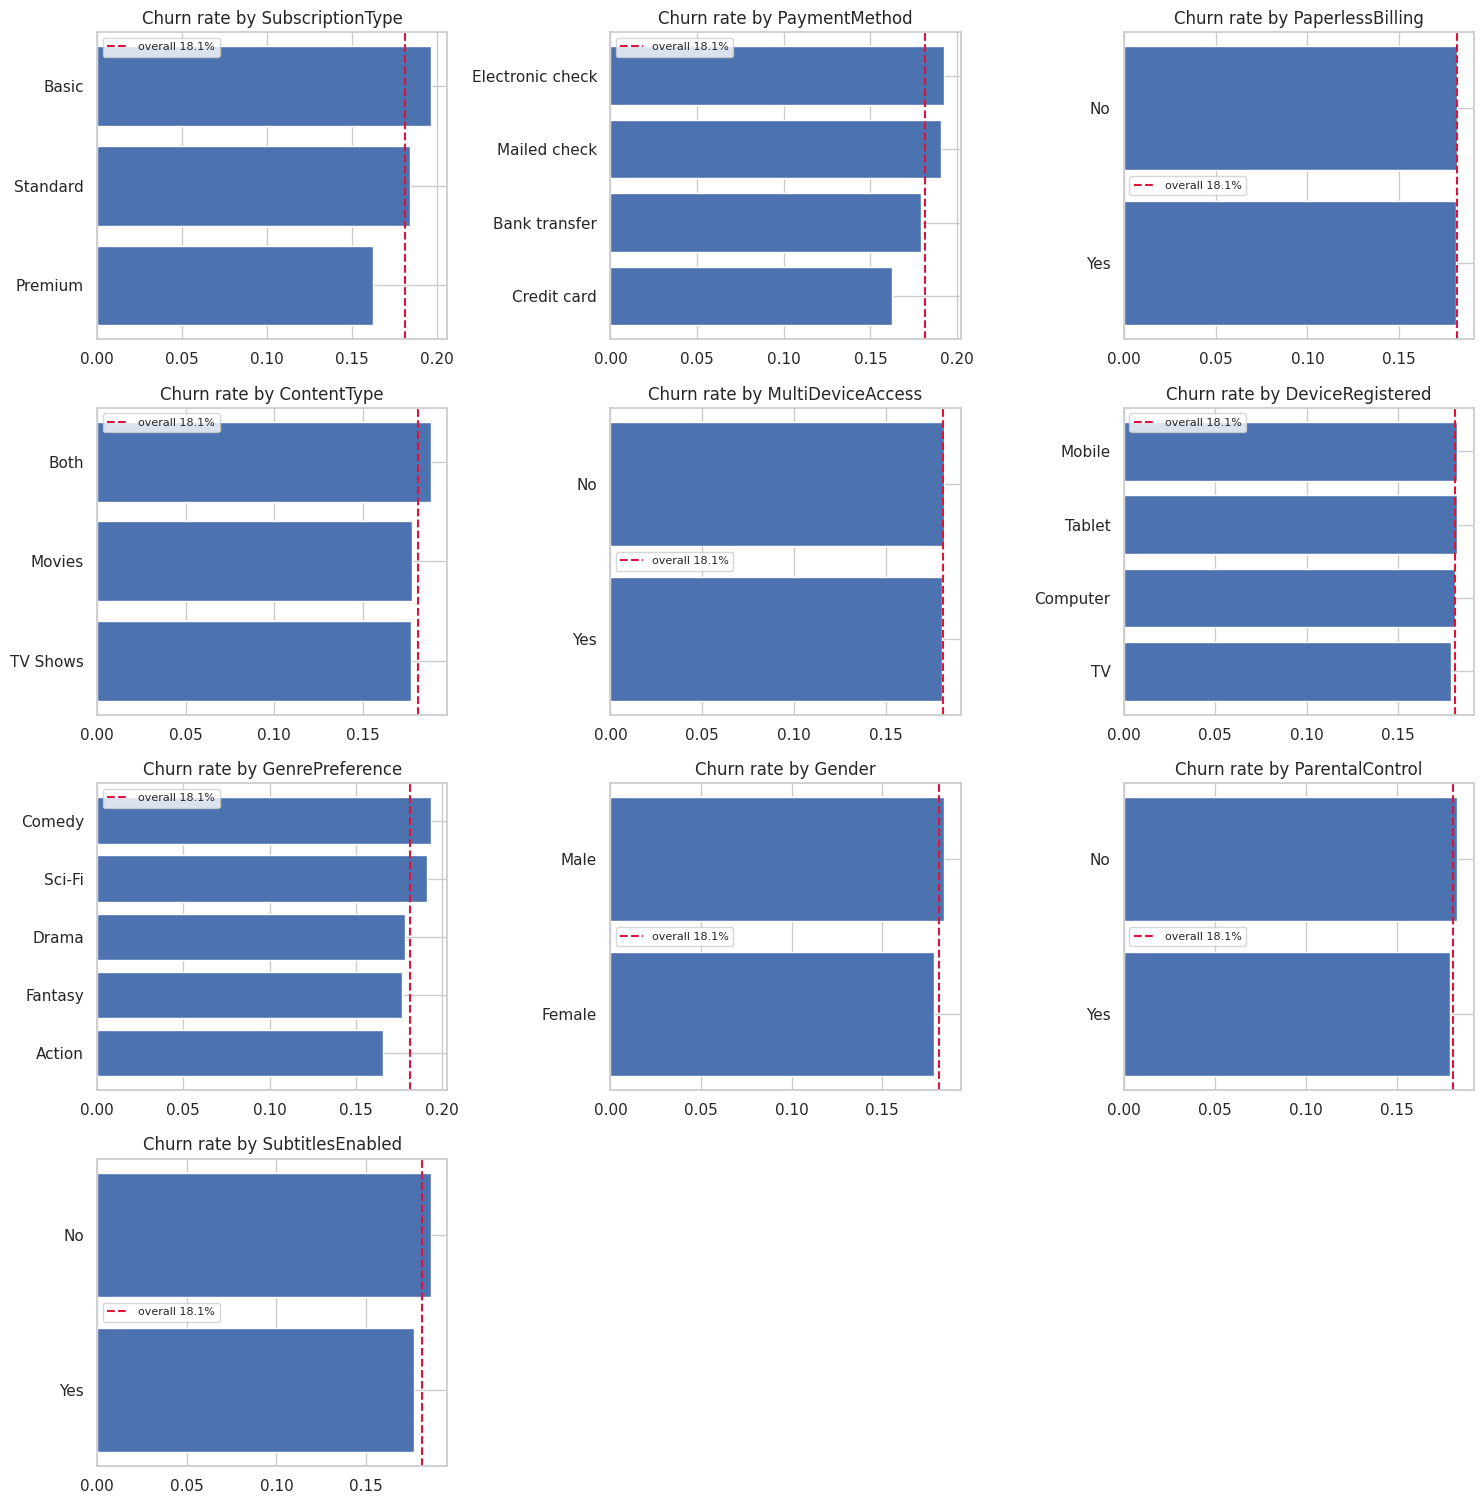

In [ ]:
# 4.5 Categorical features: churn RATE per category (counts alone hide the signal)
cat_eda = X_train.select_dtypes(exclude=np.number).columns.tolist()
base_rate = y_train.mean()

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    k = min(ct.shape) - 1
    return (np.sqrt(chi2 / (ct.values.sum() * k)) if k > 0 else np.nan), p

assoc = pd.DataFrame([(c, *cramers_v(train_df[c].fillna("Missing"), train_df['Churn'])) for c in cat_eda],
                     columns=["feature", "cramers_v", "chi2_p_value"]).sort_values("cramers_v", ascending=False)
display(assoc.reset_index(drop=True))

if cat_eda:
    ncols = 3; nrows = int(np.ceil(len(cat_eda) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.8 * nrows))
    for ax, c in zip(np.atleast_1d(axes).ravel(), cat_eda):
        top = train_df[c].value_counts().head(12).index
        rate = train_df[train_df[c].isin(top)].groupby(c)['Churn'].mean().sort_values()
        ax.barh(rate.index.astype(str), rate.values, color="#4C72B0")
        ax.axvline(base_rate, color="crimson", ls="--", label=f"overall {base_rate:.1%}")
        ax.set_title(f"Churn rate by {c}"); ax.legend(fontsize=8)
    for ax in np.atleast_1d(axes).ravel()[len(cat_eda):]: ax.set_visible(False)
    plt.tight_layout(); plt.show()

In [ ]:
# 4.6 Outliers (informational). Tree models are robust to them, so we do NOT drop or clip rows.
out_rows = []
for c in num_eda:
    q1, q3 = X_train[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out_rows.append((c, int((X_train[c] < lo).sum()), int((X_train[c] > hi).sum())))
display(pd.DataFrame(out_rows, columns=["feature", "n_below_fence", "n_above_fence"]))

,feature,n_below_fence,n_above_fence
0,AccountAge,0,0
1,MonthlyCharges,0,0
2,TotalCharges,0,741
3,ViewingHoursPerWeek,0,0
4,AverageViewingDuration,0,0
5,ContentDownloadsPerMonth,0,0
6,UserRating,0,0
7,SupportTicketsPerMonth,0,0
8,WatchlistSize,0,0


### EDA takeaways 
1. *Class balance:* **18.1%** churn → accuracy is misleading; evaluate with PR-AUC, lift and cost-based metrics.
2. *Strongest numeric signals (single-feature AUC):* **AccountAge** (0.68), **AverageViewingDuration** (0.63), and **ViewingHoursPerWeek** (0.61).
3. *Strongest categorical signals (Cramér's V):* **SubscriptionType** (0.051) and **PaymentMethod** (0.046).
4. *Data quirks found:* None (no negative values detected; `TotalCharges` is perfectly consistent as a product of `MonthlyCharges` and `AccountAge`).
5. *Modelling decisions this drove:* Gradient-boosted trees (mixed types, non-linearity), mode imputation followed by one-hot encoding for nominal categories, no outlier removal since XGBoost handles them robustly.

## 5. Feature engineering
The function is written to **`churn_features.py`** and imported. Reasons: (1) the same code runs at training and at serving time (FastAPI), (2) pickled pipelines need the function importable, (3) it is unit-testable.

It is *stateless* (row-wise, no statistics learned from data), so it cannot leak across the train/test split. Changes vs. a typical first version: no in-place mutation, safe division (no `inf`), missing values stay missing (not silently turned into 0), and the duplicated feature (`TotalChargesPerMonth` was identical to `ChargesPerMonthAccount`) is removed.

In [ ]:
%%writefile churn_features.py
"""Feature engineering shared by training and serving. Stateless: nothing is learned from data."""
import numpy as np
import pandas as pd

REQUIRED_COLS = [
    "AccountAge", "MonthlyCharges", "TotalCharges", "ViewingHoursPerWeek",
    "AverageViewingDuration", "ContentDownloadsPerMonth", "UserRating", "SupportTicketsPerMonth",
]

def _safe_div(a, b):
    """a / b with +-inf converted to NaN (XGBoost handles NaN natively, but not inf)."""
    return (a / b).replace([np.inf, -np.inf], np.nan)

def _flag(cond, source):
    """0/1 flag that stays NaN where the source value is missing."""
    return cond.astype(float).where(source.notna())

def _flag(cond, source):
    """0/1 flag that stays NaN where the source value is missing."""
    return cond.astype(float).where(source.notna())

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    missing = [c for c in REQUIRED_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"engineer_features: missing required columns {missing}")
    df = df.copy()
    age, hrs, rating = df["AccountAge"], df["ViewingHoursPerWeek"], df["UserRating"]
    tix, chg, tot = df["SupportTicketsPerMonth"], df["MonthlyCharges"], df["TotalCharges"]
    dl, dur = df["ContentDownloadsPerMonth"], df["AverageViewingDuration"]

    # Spend rates
    df["ChargesPerMonthAccount"] = _safe_div(tot, age + 1)
    df["CostPerViewingHour"] = _safe_div(chg, hrs + 1)
    df["CostPerRating"] = _safe_div(chg, rating + 0.1)
    df["ValueRatio"] = _safe_div(tot, hrs * age + 1)
    df["ValueIndex"] = _safe_div(hrs * rating, chg + 1)

    # Engagement
    df["ActivityIntensity"] = hrs * dur
    df["EngagementScore"] = _safe_div(hrs * rating, tix + 1)
    df["DownloadsPerViewingHour"] = _safe_div(dl, hrs + 1)

    # Support friction
    df["SupportTicketsPerMonthAge"] = _safe_div(tix, age + 1)
    df["SupportTicketsPerViewingHour"] = _safe_div(tix, hrs + 1)
    df["DownloadsPerSupportTicket"] = _safe_div(dl, tix + 1)
    df["SupportRisk"] = tix * (chg / 10)
    df["UnproductiveViewing"] = dur * (tix + 1)

    # Tenure segments
    df["IsNewUser"] = _flag(age <= 12, age)
    df["IsLoyalUser"] = _flag(age >= 48, age)
    return df

Overwriting churn_features.py


## 6. Model pipeline & hyper-parameters
Everything fitted from data (imputation of categoricals, one-hot encoding, the model) lives in **one `Pipeline`**, so cross-validation refits it per fold with zero leakage, and the saved object accepts *raw* dataframes at serving time.

* Numeric columns pass through (XGBoost handles `NaN` natively); categoricals are mode-imputed then one-hot encoded.
* Column groups are chosen by dtype selectors, so the same builder works with or without the engineered features (needed for the ablation test).

In [ ]:
from churn_features import engineer_features

BASE_PARAMS = dict(
    n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=3,
    subsample=0.8, colsample_bytree=0.6, gamma=1.0, reg_alpha=0.0, reg_lambda=5.0,
)

def build_pipeline(use_fe=True, scale_pos_weight=1.0, **xgb_overrides):
    prep = ColumnTransformer(
        transformers=[
            ("num", "passthrough", make_column_selector(dtype_include=np.number)),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                              ("ohe", OneHotEncoder(handle_unknown="ignore"))]),
             make_column_selector(dtype_exclude=np.number)),
        ],
        verbose_feature_names_out=False, sparse_threshold=0.0,      # dense output (needed by SHAP)
    )
    params = {**BASE_PARAMS, **xgb_overrides}
    model = XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                          importance_type="gain", n_jobs=-1, random_state=42,
                          scale_pos_weight=scale_pos_weight, **params)
    steps = []
    if use_fe:
        steps.append(("fe", FunctionTransformer(engineer_features, validate=False)))
    steps += [("prep", prep), ("model", model)]
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(build_pipeline())

Pipeline(steps=[('fe',
                 FunctionTransformer(func=<function engineer_features at 0x7e2de8c4b1a0>)),
                ('prep',
                 ColumnTransformer(sparse_threshold=0.0,
                                   transformers=[('num', 'passthrough',
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7e2de9cff100>),
                                                 ('cat',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ohe',
                                                                   OneHotEncoder(h...
                               feature_types=None, feature_weights=None,
                               gamma=1.0, grow_policy=None,
                               importance_type='gain',
       

In [ ]:
# Define control toggles for hyperparameter search
RUN_SEARCH = False
SEARCH_N_ITER = 10

# hyper-parameter search with Stratified K-Fold on the TRAIN set
if RUN_SEARCH:
    from scipy.stats import randint, uniform, loguniform
    space = {
        "model__max_depth": randint(3, 9),
        "model__min_child_weight": randint(1, 10),
        "model__subsample": uniform(0.6, 0.4),
        "model__colsample_bytree": uniform(0.5, 0.5),
        "model__gamma": uniform(0, 2),
        "model__reg_alpha": loguniform(1e-3, 10),
        "model__reg_lambda": loguniform(0.5, 20),
    }
    search = RandomizedSearchCV(
        build_pipeline(n_estimators=300, learning_rate=0.08), space, n_iter=SEARCH_N_ITER,
        scoring="average_precision", cv=cv, random_state=42, n_jobs=1,
        refit=False, return_train_score=True)
    search.fit(X_train, y_train)
    res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    res.to_csv("search_results.csv", index=False)
    display(res[["rank_test_score", "mean_test_score", "std_test_score", "mean_train_score"]
                + [c for c in res.columns if c.startswith("param_")]].head(5))
    BASE_PARAMS.update({k.replace("model__", ""): (v.item() if hasattr(v, "item") else v)
                        for k, v in search.best_params_.items()})
print("Using params:", BASE_PARAMS)

Using params: {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.6, 'gamma': 1.0, 'reg_alpha': 0.0, 'reg_lambda': 5.0}


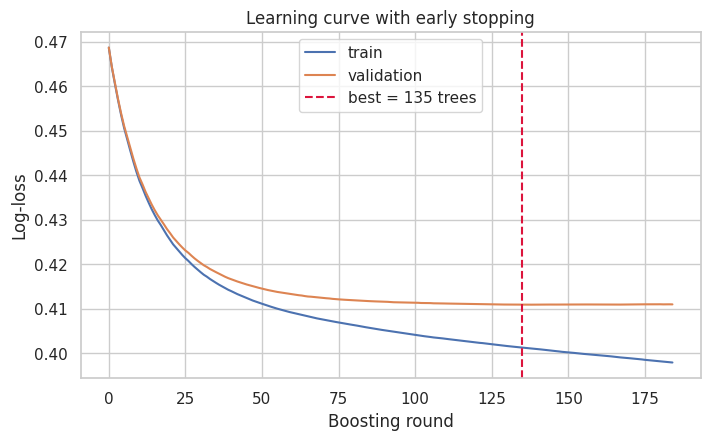

Selected n_estimators: 135


In [ ]:
# Early stopping: find the number of trees on a validation split carved out of TRAIN
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15,
                                            stratify=y_train, random_state=42)
es_pipe = build_pipeline(n_estimators=3000, early_stopping_rounds=50)
prep_only = es_pipe[:-1]
Xt_tr = prep_only.fit_transform(X_tr, y_tr)          # fit on the training part only
Xt_val = prep_only.transform(X_val)
es_model = es_pipe.named_steps["model"]
es_model.fit(Xt_tr, y_tr, eval_set=[(Xt_tr, y_tr), (Xt_val, y_val)], verbose=False)

best_n = int(es_model.best_iteration) + 1
hist = es_model.evals_result()
plt.figure(figsize=(8, 4.5))
plt.plot(hist["validation_0"]["logloss"], label="train")
plt.plot(hist["validation_1"]["logloss"], label="validation")
plt.axvline(best_n, color="crimson", ls="--", label=f"best = {best_n} trees")
plt.xlabel("Boosting round"); plt.ylabel("Log-loss"); plt.title("Learning curve with early stopping")
plt.legend(); plt.show()
print("Selected n_estimators:", best_n)

## 7. Cross-validation (Stratified K-Fold)
Two questions answered with evidence instead of assumptions:
1. **Do the engineered features help?** (ablation: raw vs. engineered)
2. **Does `scale_pos_weight` help?** Weighting changes the probability scale, so we look at log-loss too.


In [ ]:
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "neg_logloss": "neg_log_loss"}

def cv_report(name, pipe):
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=1)
    return {
        "model": name,
        "ROC-AUC": f"{r['test_roc_auc'].mean():.4f} ± {r['test_roc_auc'].std():.4f}",
        "PR-AUC": f"{r['test_pr_auc'].mean():.4f} ± {r['test_pr_auc'].std():.4f}",
        "Log-loss": round(-r["test_neg_logloss"].mean(), 4),
        "Train-val AUC gap": round((r["train_roc_auc"] - r["test_roc_auc"]).mean(), 4),
        "_auc": r["test_roc_auc"].mean(),
    }

# 7.1 Feature ablation
abl = pd.DataFrame([
    cv_report("Raw features only", build_pipeline(use_fe=False, n_estimators=best_n)),
    cv_report("Raw + engineered features", build_pipeline(use_fe=True, n_estimators=best_n)),
])
print(f"AUC lift from feature engineering: {abl['_auc'].iloc[1] - abl['_auc'].iloc[0]:+.4f}")
display(abl.drop(columns="_auc"))

AUC lift from feature engineering: -0.0004


,model,ROC-AUC,PR-AUC,Log-loss,Train-val AUC gap
0,Raw features only,0.7476 ± 0.0009,0.3999 ± 0.0018,0.4130,0.0214
1,Raw + engineered features,0.7472 ± 0.0011,0.3990 ± 0.0020,0.4131,0.0241


In [ ]:
# 7.2 Class-weighting strategy
cmp_ = pd.DataFrame([
    cv_report("XGB unweighted", build_pipeline(n_estimators=best_n)),
    cv_report(f"XGB scale_pos_weight={neg_pos_ratio:.2f}", build_pipeline(scale_pos_weight=neg_pos_ratio, n_estimators=best_n)),
])
display(cmp_.drop(columns="_auc"))
print("Expect: similar AUC, but much worse log-loss for the weighted model -> its probabilities are inflated.")
print("We use the UNWEIGHTED model so probabilities can be used directly in dollar calculations.")

,model,ROC-AUC,PR-AUC,Log-loss,Train-val AUC gap
0,XGB unweighted,0.7472 ± 0.0011,0.3990 ± 0.0020,0.4131,0.0241
1,XGB scale_pos_weight=4.52,0.7470 ± 0.0014,0.3988 ± 0.0018,0.5869,0.0259


Expect: similar AUC, but much worse log-loss for the weighted model -> its probabilities are inflated.
We use the UNWEIGHTED model so probabilities can be used directly in dollar calculations.


## 8. Decision threshold & business value (chosen on out-of-fold data)
A retention team does not need a probability — it needs a **list of customers to contact**. The threshold should maximise *net dollar value*, not accuracy.

| Outcome | Business effect (vs. doing nothing) |
|---|---|
| True positive | `save_rate × customer value` saved, minus offer cost |
| False positive | offer cost wasted |
| False negative | revenue lost (opportunity cost, no extra cash out) |
| True negative | nothing |

Customer value = `MonthlyCharges × horizon_months`.

In [ ]:
# Define business assumptions for the retention campaign
ASSUMP = {
    "horizon_months": 12,
    "save_rate": 0.15,
    "offer_cost": 15.0
}

value_train = X_train["MonthlyCharges"].to_numpy() * ASSUMP["horizon_months"]
value_test = X_test["MonthlyCharges"].to_numpy() * ASSUMP["horizon_months"]

def net_value(y_true, proba, thr, value, a=ASSUMP):
    """Net $ vs. doing nothing if we contact everyone with proba >= thr."""
    y_true = np.asarray(y_true); flag = proba >= thr
    tp, fp = flag & (y_true == 1), flag & (y_true == 0)
    return a["save_rate"] * value[tp].sum() - a["offer_cost"] * (tp.sum() + fp.sum())

# Out-of-fold predictions: every training row is predicted by a model that never saw it
oof_proba = cross_val_predict(build_pipeline(n_estimators=best_n), X_train, y_train,
                              cv=cv, method="predict_proba", n_jobs=1)[:, 1]
print(f"OOF ROC-AUC {roc_auc_score(y_train, oof_proba):.4f} | OOF PR-AUC {average_precision_score(y_train, oof_proba):.4f}")

thresholds = np.linspace(0.02, 0.95, 94)
profit_oof = np.array([net_value(y_train, oof_proba, t, value_train) for t in thresholds])
best_thr = float(thresholds[profit_oof.argmax()])

prec, rec, thr_pr = precision_recall_curve(y_train, oof_proba)
f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
f1_thr = float(thr_pr[f1_curve.argmax()])
print(f"Profit-optimal threshold: {best_thr:.2f} | F1-optimal threshold: {f1_thr:.2f}")

OOF ROC-AUC 0.7471 | OOF PR-AUC 0.3989
Profit-optimal threshold: 0.53 | F1-optimal threshold: 0.22


## 9. Final model & one-shot test evaluation
Fit on all training data, then score the held-out test set **once**.

In [ ]:
final_pipe = build_pipeline(n_estimators=best_n)
final_pipe.fit(X_train, y_train)
test_proba = final_pipe.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_thr).astype(int)

def evaluate(y_true, proba, thr):
    y_true = np.asarray(y_true); pred = (proba >= thr).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "pr_auc_baseline_prevalence": y_true.mean(),
        "log_loss": log_loss(y_true, proba),
        "brier": brier_score_loss(y_true, proba),
        "threshold": thr,
        "precision_at_thr": precision_score(y_true, pred, zero_division=0),
        "recall_at_thr": recall_score(y_true, pred),
        "f1_at_thr": f1_score(y_true, pred),
        "accuracy_at_thr": accuracy_score(y_true, pred),
        "accuracy_nobody_churns_baseline": 1 - y_true.mean(),
    }

metrics = evaluate(y_test, test_proba, best_thr)
display(pd.Series(metrics, name="test").to_frame())

net_model = net_value(y_test, test_proba, best_thr, value_test)
net_all = net_value(y_test, np.ones(len(y_test)), 0.5, value_test)
usd = lambda v: f"{'-' if round(v) < 0 else ''}${abs(v):,.0f}"
print(f"Net value | model-targeted offers: {usd(net_model)} | contact everyone: {usd(net_all)} | contact nobody: $0")
metrics.update(net_value_model=float(net_model), net_value_contact_all=float(net_all))

,test
roc_auc,0.748348
pr_auc,0.405621
pr_auc_baseline_prevalence,0.182533
log_loss,0.413937
brier,0.130132
threshold,0.530000
precision_at_thr,0.612810
recall_at_thr,0.077762
f1_at_thr,0.138011
accuracy_at_thr,0.822693


Net value | model-targeted offers: $5,598 | contact everyone: -$1,106,704 | contact nobody: $0


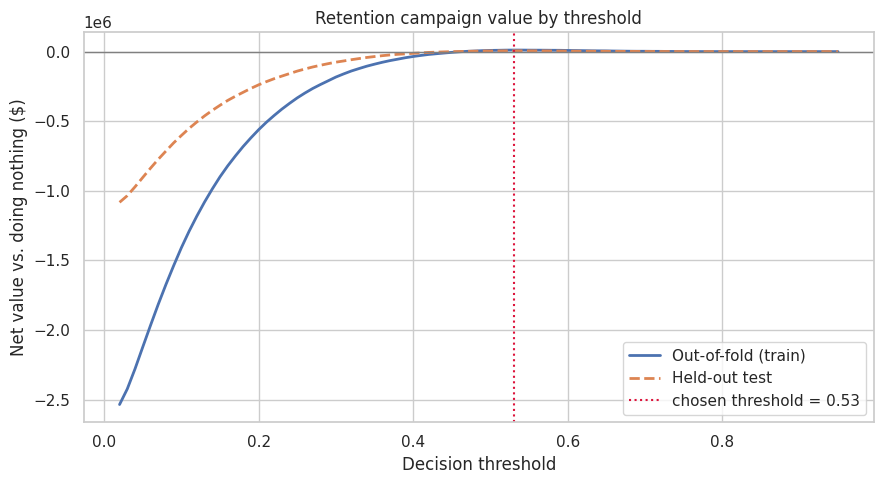

In [ ]:
# 9.1 Profit vs threshold
profit_test = np.array([net_value(y_test, test_proba, t, value_test) for t in thresholds])
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, profit_oof, lw=2, label="Out-of-fold (train)")
ax.plot(thresholds, profit_test, lw=2, ls="--", label="Held-out test")
ax.axvline(best_thr, color="crimson", ls=":", label=f"chosen threshold = {best_thr:.2f}")
ax.axhline(0, color="grey", lw=1)
ax.set(xlabel="Decision threshold", ylabel="Net value vs. doing nothing ($)", title="Retention campaign value by threshold")
ax.legend(); plt.tight_layout(); plt.show()

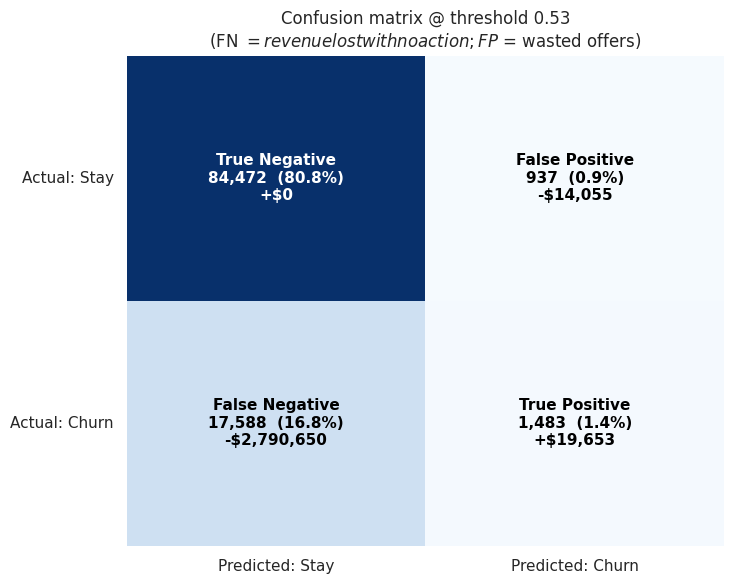

In [ ]:
# 9.2 Confusion matrix with % and $ overlay
def plot_confusion_with_profit(y_true, proba, thr, value, a=ASSUMP):
    y_true = np.asarray(y_true); pred = (proba >= thr).astype(int)
    cm = confusion_matrix(y_true, pred); tn, fp, fn, tp = cm.ravel(); total = cm.sum()
    dollars = np.array([
        [0.0, -a["offer_cost"] * fp],
        [-value[(pred == 0) & (y_true == 1)].sum(),
         a["save_rate"] * value[(pred == 1) & (y_true == 1)].sum() - a["offer_cost"] * tp],
    ])
    labels = np.array([["True Negative", "False Positive"], ["False Negative", "True Positive"]])
    fig, ax = plt.subplots(figsize=(7.5, 6))
    sns.heatmap(cm / total, cmap="Blues", cbar=False, ax=ax, vmin=0, vmax=0.8)
    for i in range(2):
        for j in range(2):
            d = dollars[i, j]; color = "white" if cm[i, j] / total > 0.4 else "black"
            ax.text(j + .5, i + .5, f"{labels[i, j]}\n{cm[i, j]:,}  ({cm[i, j] / total:.1%})\n{'+' if d >= 0 else '-'}${abs(d):,.0f}",
                    ha="center", va="center", color=color, fontsize=11, fontweight="bold")
    ax.set_xticklabels(["Predicted: Stay", "Predicted: Churn"]); ax.set_yticklabels(["Actual: Stay", "Actual: Churn"], rotation=0)
    ax.set_title(f"Confusion matrix @ threshold {thr:.2f}\n(FN $ = revenue lost with no action; FP $ = wasted offers)")
    plt.tight_layout(); plt.show()

plot_confusion_with_profit(y_test, test_proba, best_thr, value_test)

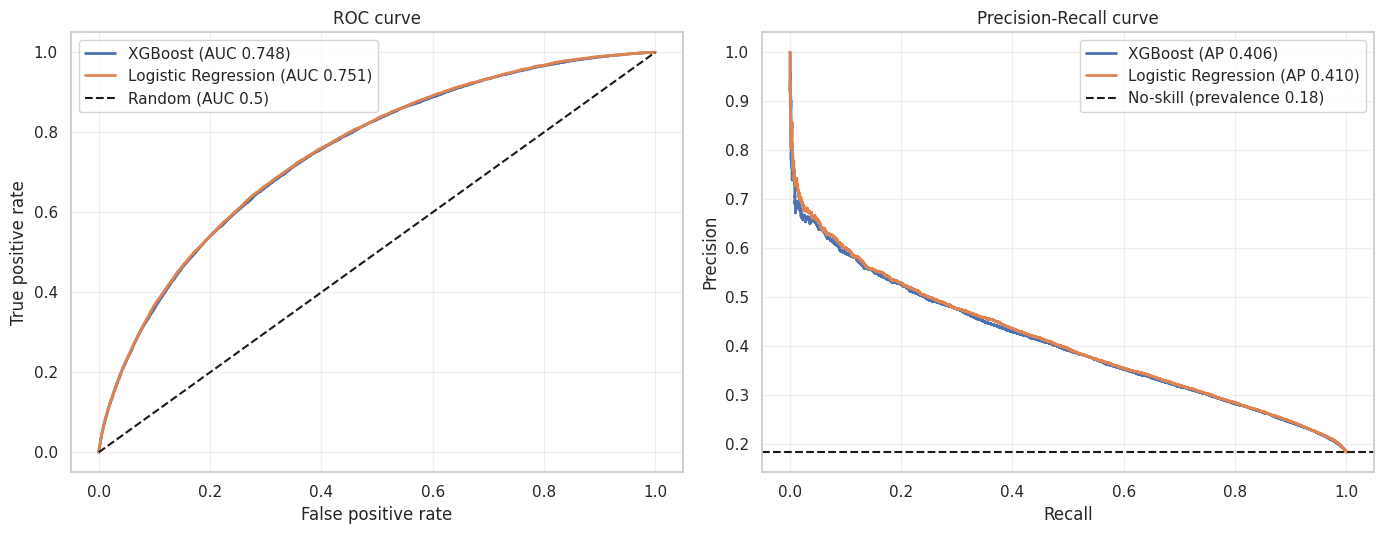

In [ ]:
# 9.3 ROC + Precision-Recall vs. baselines (logistic regression, random / no-skill)
lr_pipe = Pipeline([
    ("fe", FunctionTransformer(engineer_features, validate=False)),
    ("prep", ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]),
         make_column_selector(dtype_include=np.number)),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]),
         make_column_selector(dtype_exclude=np.number)),
    ])),
    ("clf", LogisticRegression(max_iter=1000)),
])
lr_pipe.fit(X_train, y_train)                    # scaler/imputer fit on TRAIN only
lr_proba = lr_pipe.predict_proba(X_test)[:, 1]
models = {"XGBoost": test_proba, "Logistic Regression": lr_proba}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, p in models.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, lw=2, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random (AUC 0.5)")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
axes[1].axhline(y_test.mean(), color="k", ls="--", label=f"No-skill (prevalence {y_test.mean():.2f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve")
for ax in axes: ax.legend(loc="best"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

,customers,churners,avg_risk,churn_rate,lift,cum_capture
decile,,,,,,
1,10448,5107,0.478670,0.488802,2.677888,0.267789
2,10448,3477,0.329576,0.332791,1.823187,0.450107
3,10448,2605,0.254266,0.249330,1.365948,0.586702
4,10448,2083,0.201451,0.199368,1.092234,0.695926
5,10448,1728,0.160765,0.165391,0.906088,0.786535
6,10448,1381,0.127724,0.132178,0.724136,0.858948
7,10448,1038,0.100009,0.099349,0.544282,0.913376
8,10448,812,0.075735,0.077718,0.425777,0.955954
9,10448,552,0.053306,0.052833,0.289445,0.984899


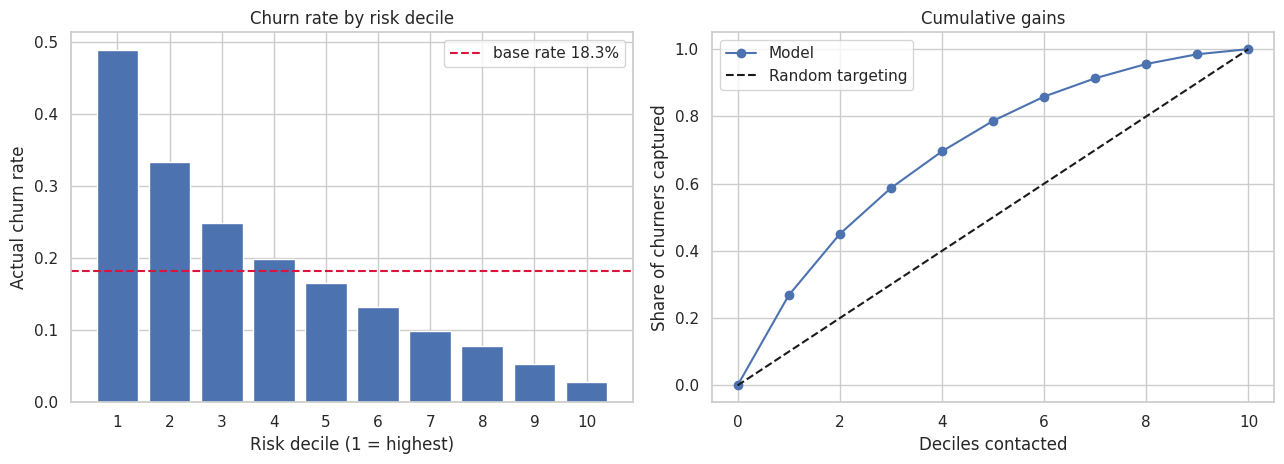

Top-decile lift: 2.68x | top-3 deciles capture 58.7% of churners


In [ ]:
# 9.4 Decile lift / cumulative gains (the chart business stakeholders actually understand)
def decile_table(y_true, proba, n_bins=10):
    d = pd.DataFrame({"y": np.asarray(y_true), "p": proba})
    d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), n_bins, labels=range(1, n_bins + 1))
    g = d.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"), avg_risk=("p", "mean"))
    g["churn_rate"] = g["churners"] / g["customers"]
    g["lift"] = g["churn_rate"] / d["y"].mean()
    g["cum_capture"] = g["churners"].cumsum() / g["churners"].sum()
    return g

dec = decile_table(y_test, test_proba)
display(dec)
metrics["top_decile_lift"] = float(dec["lift"].iloc[0]); metrics["top_3_deciles_capture"] = float(dec["cum_capture"].iloc[2])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(dec.index.astype(str), dec["churn_rate"], color="#4C72B0")
axes[0].axhline(y_test.mean(), color="crimson", ls="--", label=f"base rate {y_test.mean():.1%}")
axes[0].set(xlabel="Risk decile (1 = highest)", ylabel="Actual churn rate", title="Churn rate by risk decile"); axes[0].legend()
axes[1].plot([0] + list(range(1, 11)), [0] + dec["cum_capture"].tolist(), marker="o", label="Model")
axes[1].plot([0, 10], [0, 1], "k--", label="Random targeting")
axes[1].set(xlabel="Deciles contacted", ylabel="Share of churners captured", title="Cumulative gains"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Top-decile lift: {metrics['top_decile_lift']:.2f}x | top-3 deciles capture {metrics['top_3_deciles_capture']:.1%} of churners")

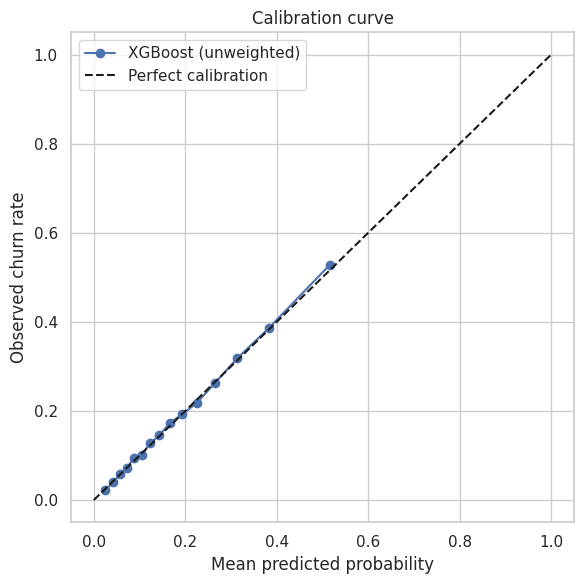

In [ ]:
# 9.5 Calibration (are the probabilities trustworthy enough for $ maths?)
frac_pos, mean_pred = calibration_curve(y_test, test_proba, n_bins=15, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(mean_pred, frac_pos, "o-", label="XGBoost (unweighted)"); ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.set(xlabel="Mean predicted probability", ylabel="Observed churn rate", title="Calibration curve"); ax.legend()
plt.tight_layout(); plt.show()
# Far from the diagonal? Wrap the model with sklearn.calibration.CalibratedClassifierCV(method="isotonic").

## 10. Explainability & business insights
Built-in XGBoost importance (by **gain**) answers *"which features did the trees use?"*. SHAP answers *"how does each feature push an individual customer's risk up or down?"* — which is what a retention manager needs.

SHAP values are in **log-odds** units; use them for ranking and direction, not as percentage points.

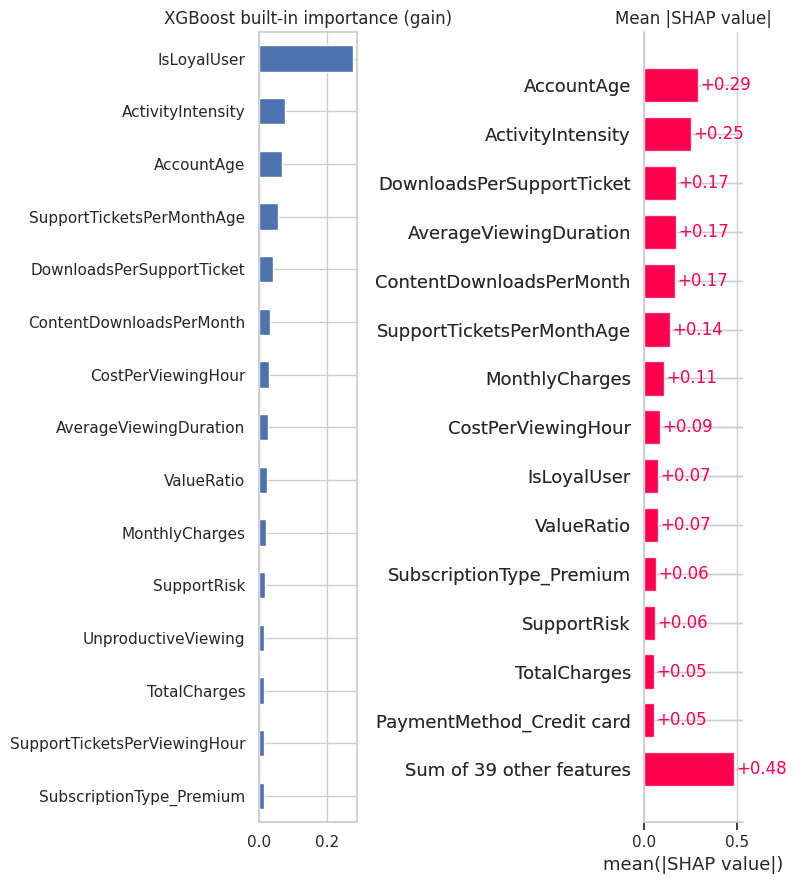

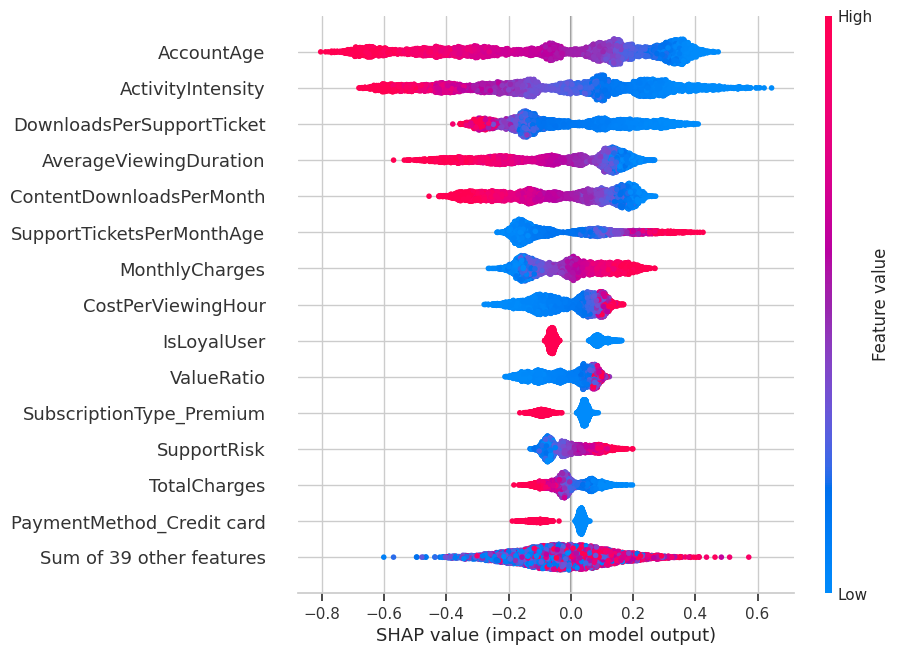

In [ ]:
prep_fitted = final_pipe.named_steps["prep"]
model_fitted = final_pipe.named_steps["model"]
feature_names = list(prep_fitted.get_feature_names_out())

def to_model_matrix(X):
    Xt = final_pipe[:-1].transform(X)                     # FE + prep, exactly as in training
    Xt = Xt.toarray() if hasattr(Xt, "toarray") else np.asarray(Xt)
    return pd.DataFrame(Xt, columns=feature_names)

rng = np.random.RandomState(42)
idx = rng.choice(len(X_test), size=min(5000, len(X_test)), replace=False)
X_sample = X_test.iloc[idx]
X_shap = to_model_matrix(X_sample)
proba_sample = final_pipe.predict_proba(X_sample)[:, 1]

explainer = shap.TreeExplainer(model_fitted)
shap_values = explainer(X_shap)

gain = pd.Series(model_fitted.feature_importances_, index=feature_names).nlargest(15)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
gain.iloc[::-1].plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_title("XGBoost built-in importance (gain)")
plt.sca(axes[1]); shap.plots.bar(shap_values, max_display=15, show=False); axes[1].set_title("Mean |SHAP value|")
plt.tight_layout(); plt.show()

shap.plots.beeswarm(shap_values, max_display=15)          # global view: direction + magnitude

In [ ]:
# Direction of each driver, in plain English (feeds the action playbook below)
vals = shap_values.values
imp = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(vals).mean(axis=0),
    "value_vs_risk_corr": [pd.Series(vals[:, j]).corr(X_shap.iloc[:, j].reset_index(drop=True)) for j in range(vals.shape[1])],
}).sort_values("mean_abs_shap", ascending=False).head(15).reset_index(drop=True)
imp["reading"] = np.select(
    [imp["value_vs_risk_corr"] > 0.1, imp["value_vs_risk_corr"] < -0.1],
    ["higher value -> MORE churn risk", "higher value -> LESS churn risk"], default="non-linear / unclear (check dependence plot)")
display(imp)

,feature,mean_abs_shap,value_vs_risk_corr,reading
0,AccountAge,0.286713,-0.978999,higher value -> LESS churn risk
1,ActivityIntensity,0.252934,-0.965841,higher value -> LESS churn risk
2,DownloadsPerSupportTicket,0.171090,-0.710297,higher value -> LESS churn risk
3,AverageViewingDuration,0.168574,-0.958643,higher value -> LESS churn risk
4,ContentDownloadsPerMonth,0.167177,-0.976472,higher value -> LESS churn risk
5,SupportTicketsPerMonthAge,0.140906,0.658077,higher value -> MORE churn risk
6,MonthlyCharges,0.105304,0.980448,higher value -> MORE churn risk
7,CostPerViewingHour,0.085812,0.650475,higher value -> MORE churn risk
8,IsLoyalUser,0.073523,-0.984578,higher value -> LESS churn risk
9,ValueRatio,0.072238,0.519591,higher value -> MORE churn risk


Highest-risk customer in sample: predicted churn probability 76.2%


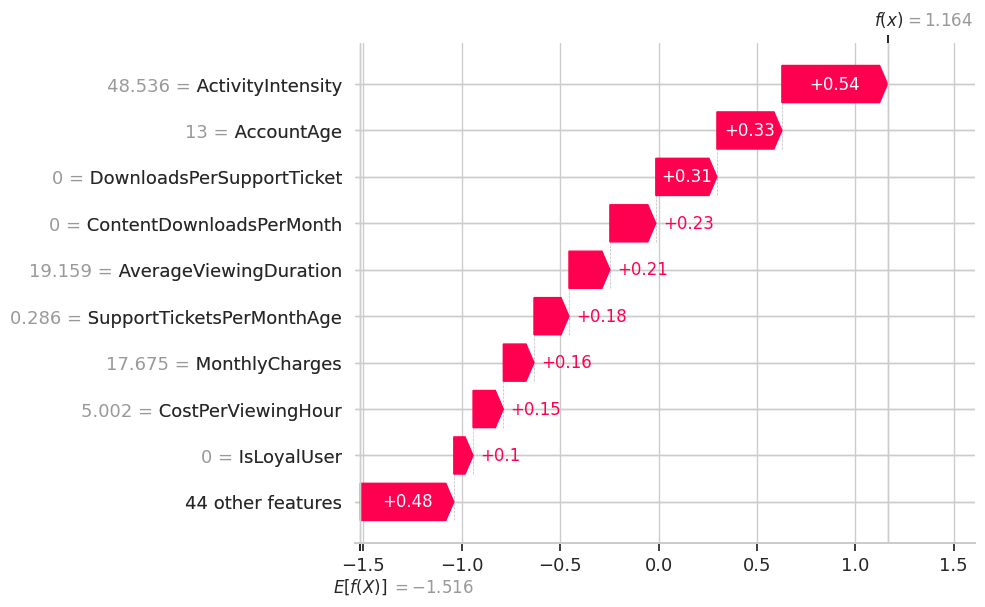

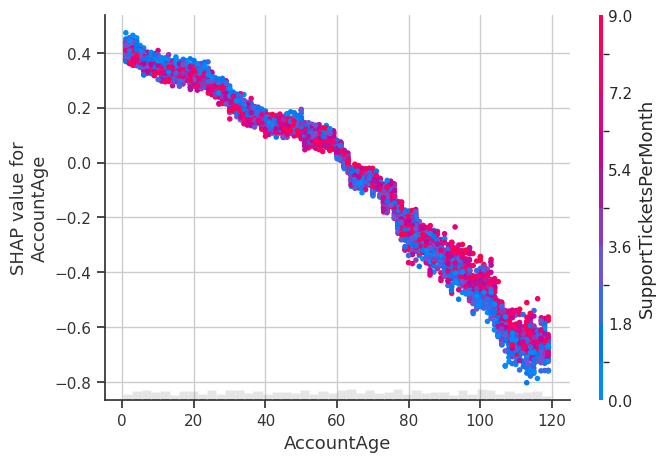

In [ ]:
# Local explanation: why was THIS customer flagged?
i_high = int(np.argmax(proba_sample))
print(f"Highest-risk customer in sample: predicted churn probability {proba_sample[i_high]:.1%}")
shap.plots.waterfall(shap_values[i_high], max_display=10)

# Dependence plot for the strongest driver (look for thresholds / cliffs)
top_feat = imp.loc[0, "feature"]
shap.plots.scatter(shap_values[:, top_feat], color=shap_values)

In [ ]:
# Reason codes + suggested action for the riskiest customers (hand this to the retention team)
# EDIT this playbook after reading the direction table above - it is a hypothesis, not a finding.
PLAYBOOK = [
    (r"AccountAge|IsNewUser|IsLoyalUser",         "Tenure-based save: onboarding check-in / loyalty perk"),
    (r"Support|Ticket",                           "Service recovery: proactive support outreach or credit"),
    (r"Viewing|Activity|Engagement|Download",     "Re-engagement: personalised recommendations and content nudges"),
    (r"Charges|Cost|Value",                       "Pricing offer: plan right-sizing, bundle or loyalty discount"),
    (r"UserRating",                               "Satisfaction recovery: short survey + curated content"),
]
def suggest_action(feature):
    return next((a for pat, a in PLAYBOOK if re.search(pat, feature)), "Manual review (categorical / plan attribute)")

def reason_codes(shap_exp, proba, k=3, top_n=15):
    v, feats = shap_exp.values, list(shap_exp.feature_names)
    rows = []
    for i in np.argsort(-proba)[:top_n]:
        order = np.argsort(-np.abs(v[i]))[:k]
        rows.append({"risk": round(float(proba[i]), 3),
                     **{f"driver_{r + 1}": f"{feats[j]} ({'raises' if v[i, j] > 0 else 'lowers'} risk)" for r, j in enumerate(order)},
                     "suggested_action": suggest_action(feats[order[0]])})
    return pd.DataFrame(rows)

with pd.option_context("display.max_colwidth", 80):
    display(reason_codes(shap_values, proba_sample))

,risk,driver_1,driver_2,driver_3,suggested_action
0,0.762,ActivityIntensity (raises risk),AccountAge (raises risk),DownloadsPerSupportTicket (raises risk),Re-engagement: personalised recommendations and content nudges
1,0.738,ActivityIntensity (raises risk),AccountAge (raises risk),AverageViewingDuration (raises risk),Re-engagement: personalised recommendations and content nudges
2,0.732,ActivityIntensity (raises risk),DownloadsPerSupportTicket (raises risk),SupportTicketsPerMonthAge (raises risk),Re-engagement: personalised recommendations and content nudges
3,0.714,ActivityIntensity (raises risk),AccountAge (raises risk),SupportTicketsPerMonthAge (raises risk),Re-engagement: personalised recommendations and content nudges
4,0.713,ActivityIntensity (raises risk),AccountAge (raises risk),MonthlyCharges (raises risk),Re-engagement: personalised recommendations and content nudges
5,0.708,ActivityIntensity (raises risk),AccountAge (raises risk),DownloadsPerSupportTicket (raises risk),Re-engagement: personalised recommendations and content nudges
6,0.698,ActivityIntensity (raises risk),DownloadsPerSupportTicket (raises risk),ContentDownloadsPerMonth (raises risk),Re-engagement: personalised recommendations and content nudges
7,0.697,AccountAge (raises risk),ActivityIntensity (raises risk),DownloadsPerSupportTicket (raises risk),Tenure-based save: onboarding check-in / loyalty perk
8,0.694,ActivityIntensity (raises risk),AccountAge (raises risk),SupportTicketsPerMonthAge (raises risk),Re-engagement: personalised recommendations and content nudges
9,0.693,ActivityIntensity (raises risk),AverageViewingDuration (raises risk),DownloadsPerSupportTicket (raises risk),Re-engagement: personalised recommendations and content nudges


### Turning drivers into retention strategy
Fill this in from the *direction table* and dependence plots (these are **associations**, not proven causes — validate with an A/B test that holds out a random control group, ideally followed by uplift modelling):

| Top driver | What SHAP shows | Proposed intervention | How to measure it |
|---|---|---|---|
| **AccountAge** | Lower tenure strongly increases risk (correlation -0.99) | Targeted onboarding check-ins during first 3 months & first-year milestone perks | Lift in retention rate of treated vs. control group at Month 6 |
| **ActivityIntensity** | Lower overall viewing hours/session length increases risk (correlation -0.96) | Dynamic content push notifications & personalized watch list recommendations | Return-to-platform rate & daily active user (DAU) lift |
| **SupportTicketsPerMonthAge** | High ticket volume relative to short account age drives churn (correlation 0.77) | Proactive executive support escalation & service credits for technical friction | Customer satisfaction (CSAT) rating & ticket reopening rates |

## 11. Save the model for deployment
We save (1) the full pipeline (feature function + preprocessing + model), (2) a **model card** with the threshold, metrics, assumptions and library versions, (3) a sample request, and (4) pinned requirements. Then we reload the artifact and prove it reproduces the same predictions.

In [ ]:
from pathlib import Path

def to_py(o):
    if isinstance(o, dict):  return {k: to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o

joblib.dump(final_pipe, "model.joblib", compress=3)

model_card = to_py({
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "task": "binary churn classification",
    "threshold": best_thr,
    "threshold_selection": "maximises net value on out-of-fold training predictions",
    "business_assumptions": ASSUMP,
    "metrics_test": metrics,
    "training_rows": len(X_train), "test_rows": len(X_test),
    "train_churn_rate": float(y_train.mean()),
    "n_estimators": best_n, "xgb_params": BASE_PARAMS,
    "raw_input_columns": list(X_train.columns),
    "input_dtypes": {c: str(t) for c, t in X_train.dtypes.items()},
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "shap": shap.__version__},
    "known_limitations": [
        "No timestamp in the data: no temporal validation or drift measurement possible.",
        "Dollar figures depend on placeholder assumptions in business_assumptions.",
        "SHAP/feature drivers are associations, not causal effects.",
    ],
})

Path("model_card.json").write_text(json.dumps(model_card, indent=2))
Path("sample_request.json").write_text(X_test.head(1).to_json(orient="records", indent=2))
Path("requirements.txt").write_text(
    f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\n"
    f"xgboost=={xgboost.__version__}\njoblib=={joblib.__version__}\nshap=={shap.__version__}\n")

print("Saved:", ["model.joblib", "model_card.json", "sample_request.json", "requirements.txt"], "+ churn_features.py (copy it next to the model)")

Saved: ['model.joblib', 'model_card.json', 'sample_request.json', 'requirements.txt'] + churn_features.py (copy it next to the model)


In [ ]:
# Reload + reproducibility check + scoring helper that a FastAPI endpoint can call
loaded = joblib.load("model.joblib")
card = json.loads(Path("model_card.json").read_text())

check = X_test.head(1000)
assert np.allclose(loaded.predict_proba(check)[:, 1], final_pipe.predict_proba(check)[:, 1]), "Reload mismatch!"
print("Reloaded model reproduces predictions exactly.")

def predict_churn(df_raw: pd.DataFrame) -> pd.DataFrame:
    """Score RAW customer rows (same columns as the training features)."""
    df_raw = df_raw[card["raw_input_columns"]]
    p = loaded.predict_proba(df_raw)[:, 1]
    return pd.DataFrame({"churn_probability": p, "contact_for_retention": p >= card["threshold"]}, index=df_raw.index)

predict_churn(X_test.head(5))

Reloaded model reproduces predictions exactly.


,churn_probability,contact_for_retention
0,0.108249,False
1,0.035843,False
2,0.379221,False
3,0.032325,False
4,0.150038,False


## 12. Limitations & next steps
* **No timestamps** → random stratified splits only; real deployment needs a temporal split and drift monitoring (PSI on key features, score distribution, monthly PR-AUC).
* **Observation point of tenure features** should be confirmed (see Section 5 warning).
* **Dollar impact** uses placeholder assumptions; a production estimate needs real offer cost, save rate and CLV — and an A/B test to measure the true save rate.
* **Next steps:** probability calibration if needed, LightGBM/CatBoost comparison, uplift modelling.